<a href="https://colab.research.google.com/github/Beatricepapi/ml-campus_data_project-colab/blob/main/Beatrice_Papi_Machine_Learning_with_Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Campus Synthetic Dataset**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

#**Project Introduction**

##Project Title
Exploring Campus Nature and Human Experience Through Data and Machine Learning

###Research Question
How can data collected during a campus nature walk be used to investigate the relationship between environmental characteristics and human experience?

###Project Aim
The aim of this project is to explore how different environmental characteristics around the ATU Galway campus may relate to people's wellbeing and experiences.

Using Python, I will clean, explore and visualise the campus dataset to identify patterns and possible relationships between environmental factors, such as sound levels, weather, foot traffic and natural features, and human experiences, such as stress, wellbeing and connection with nature.

I will also apply machine-learning techniques to investigate these patterns and evaluate the results.

##Weekly Decision Logs

### Decision 1 – Initial Dataset Cleaning – 08/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | My dataset contained 994 rows and 27 columns, with many empty rows and missing values. |
| **Decision Taken** | I created a copy of the dataset, removed rows without a location and deleted four completely empty columns. |
| **Justification** | I wanted to keep the original data unchanged and work only with the recorded observations. |
| **Evidence** | The dataset was reduced from 994 rows and 27 columns to 135 rows and 23 columns. |
| **AI Use** | I used ChatGPT to help me understand the Pandas cleaning commands. |
| **Reflection / Learning** | I learned how to inspect a dataset, identify missing data and remove unnecessary rows and columns. |

### Decision 2 – Handling Missing Values and Inconsistent Text – 15/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | After cleaning, some nature-related columns still had missing values and inconsistent text entries. |
| **Decision Taken** | I checked the remaining missing values and duplicates, kept missing values unchanged, and removed extra spaces from text entries. |
| **Justification** | I did not want to remove useful observations or treat missing values as if plants were absent. |
| **Evidence** | There were 0 duplicate rows. In the moss or lichen column, the two versions of `Some` were combined into 65 entries. |
| **AI Use** | I used ChatGPT to help identify a column-name error and understand text standardisation. |
| **Reflection / Learning** | I learned that small text differences can affect results and that missing values need careful consideration. |

### Decision 3 – Data Visualisation and Encoding – 22/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | I needed to visualise my data and prepare categorical variables for correlation analysis. |
| **Decision Taken** | I created bar charts, encoded sound levels, foot traffic, wellbeing, stress and ease ratings, and created a Spearman correlation heatmap. |
| **Justification** | I chose bar charts because they helped me compare observations. I used ordinal encoding because the categories have a natural order, and Spearman correlation to investigate relationships. |
| **Evidence** | All five variables were encoded successfully. The heatmap showed a correlation of 0.56 between sound level and foot traffic and −0.60 between wellbeing and stress. |
| **AI Use** | I used ChatGPT to help write Python code, correct errors, understand encoding and interpret the graphs. |
| **Reflection / Learning** | I learned how to convert categorical data into numbers and use a correlation matrix to identify relationships. I also learned that correlation does not prove causation. |

#**Dataset**

In [3]:
df = pd.read_csv(
    '/content/drive/MyDrive/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)


##Inspect the Dataset structure

In [4]:
print(df.shape)
print('\nThe first 5 rows of my dataset:')
print(df.head())


(994, 27)

The first 5 rows of my dataset:
  recorder_id       date                        location        weather  \
0     R26_001  9/22/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  9/22/2026                L02 LibraryGreen          Sunny   
2     R26_001  9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  9/22/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0           

##Check Dataset information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

##Check for missing values

In [6]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
recorder_id                              795
date                                     859
location                                 859
weather                                  859
temperature_c                            859
sound level                              859
foot_traffic                             859
primary_sound_type_urban                 859
other_sound_type_urban                   862
primary_sound_type_nature                859
other_sound_type_nature                  861
insects_count                            859
birds_count                              859
trees_presence                           864
native_or_wild_plant_presence            871
ornnamental_or_planted_plant_presence    897
moss_or_lichen_presence                  895
wellbeing_rating                         859
ease_rating                              859
stress_rating                            859
nature_connection_experience_rating      859
most_notable_nature_element           

##Check for duplicate rows

In [7]:
print("\nDuplicate rows:")
print(df.duplicated().sum())



Duplicate rows:
844


##Create a copy o the original Dataset

In [8]:
df_clean = df.copy()

##Remove rows without a reorded location

In [9]:
df_clean = df_clean.dropna(subset=['location'])

##Remove completely empty columns

In [10]:
df_clean = df_clean.dropna(axis=1, how='all')

##Display the cleaned dataset dimensions

In [11]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (994, 27)
Cleaned dataset: (135, 23)


##Display the first five cleaned rows

In [12]:
display(df_clean.head())


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN


#**Check Remaining Missing Values and Duplicates**


##Check missing values in the cleaned dataset

In [32]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
recorder_id                               0
date                                      0
location                                  0
weather                                   0
temperature_c                             0
sound level                               0
foot_traffic                              0
primary_sound_type_urban                  0
other_sound_type_urban                    3
primary_sound_type_nature                 0
other_sound_type_nature                   2
insects_count                             0
birds_count                               0
trees_presence                            5
native_or_wild_plant_presence            12
ornnamental_or_planted_plant_presence    38
moss_or_lichen_presence                  36
wellbeing_rating                          0
ease_rating                               0
stress_rating                             0
nature_connection_experience_rating       0
most_notable_nature_element              15
o

##Check duplicate rows in the cleaned dataset

In [14]:
print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())



Duplicate rows after cleaning:
0


##Inspect the values in nature-related columns

In [15]:
nature_columns = [
    'trees_presence',
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence'
]

for col in nature_columns:
    print("\n", col)
    print(df_clean[col].value_counts(dropna=False))



 trees_presence
trees_presence
Many          101
One or two     29
NaN             5
Name: count, dtype: int64

 native_or_wild_plant_presence
native_or_wild_plant_presence
Some     78
Many     45
NaN      12
Name: count, dtype: int64

 ornnamental_or_planted_plant_presence
ornnamental_or_planted_plant_presence
Some     60
NaN      38
Many     37
Name: count, dtype: int64

 moss_or_lichen_presence
moss_or_lichen_presence
Some     63
NaN      36
Many     34
Some      2
Name: count, dtype: int64


##Remove extra spaces from text values

In [16]:
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

##Check moss or lichen values again

In [17]:
print(df_clean['moss_or_lichen_presence'].value_counts(dropna=False))


moss_or_lichen_presence
Some    65
NaN     36
Many    34
Name: count, dtype: int64


#**Data Exploration and Visualisation**

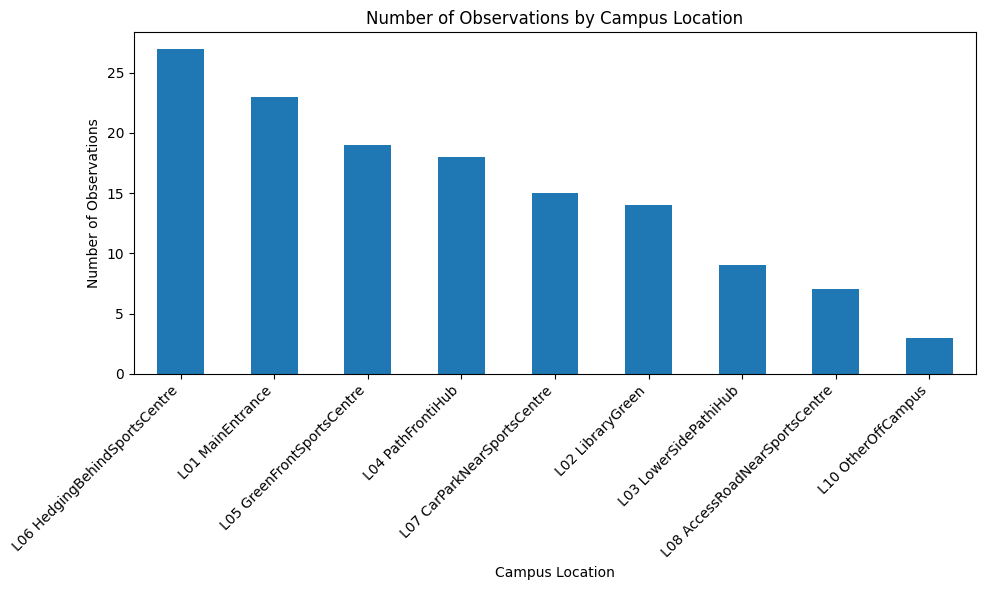

In [18]:

import matplotlib.pyplot as plt

#Count observations at each campus location
location_counts = df_clean['location'].value_counts()

#Create a bar chart
plt.figure(figsize=(10, 6))
location_counts.plot(kind='bar')

plt.title('Number of Observations by Campus Location')
plt.xlabel('Campus Location')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


###Interpretation - Number of Observations by Campus Location

I chose to use a bar chart because this is how I was imagining the data in my head. I thought it would be the easiest way to visually compare the number of observations collected at each campus location and clearly see the differences between them.

The bar chart shows that L06 HedgingBehindSportsCentre had the highest number of observations (27), followed by L01 MainEntrance (23). L10 OtherOffCampus had the lowest number of observations (3).

Looking at the graph, I noticed that the observations were not evenly distributed across the different locations. Some places had many more observations than others.

I think this is important because locations with more observations could have a greater influence on the overall results, while locations with fewer observations might be harder to compare reliably.

Creating this graph helped me understand how the observations were distributed across campus. It also gave me a clearer picture of the dataset before moving on to investigate how environmental factors, such as sound levels and natural features, might be related to people's stress and wellbeing.

##Exploring Sound Levels and Stress

###Explanation - Comparing Sound Levels and Stress Ratings

In this section, I wanted to investigate whether different sound levels around the campus were related to how stressed or calm people felt.

I used the `sound_level` and `stress_rating` columns from my cleaned dataset. Both columns contain categorical data, so I decided to use `pd.crosstab()` to compare them.

I also used `normalize='index'` to calculate percentages for each sound level. I thought percentages would make the comparison easier because the number of observations was not the same for every sound category.

###Compare sound levels with stress ratings

stress_rating,Mostly calm,Neutral,Stressful,Very calm,Very stressful
sound level,,,,,
Loud,41.2,41.2,11.8,5.9,0.0
Moderate,45.0,30.0,5.0,18.3,1.7
Quiet,43.1,22.4,3.4,31.0,0.0


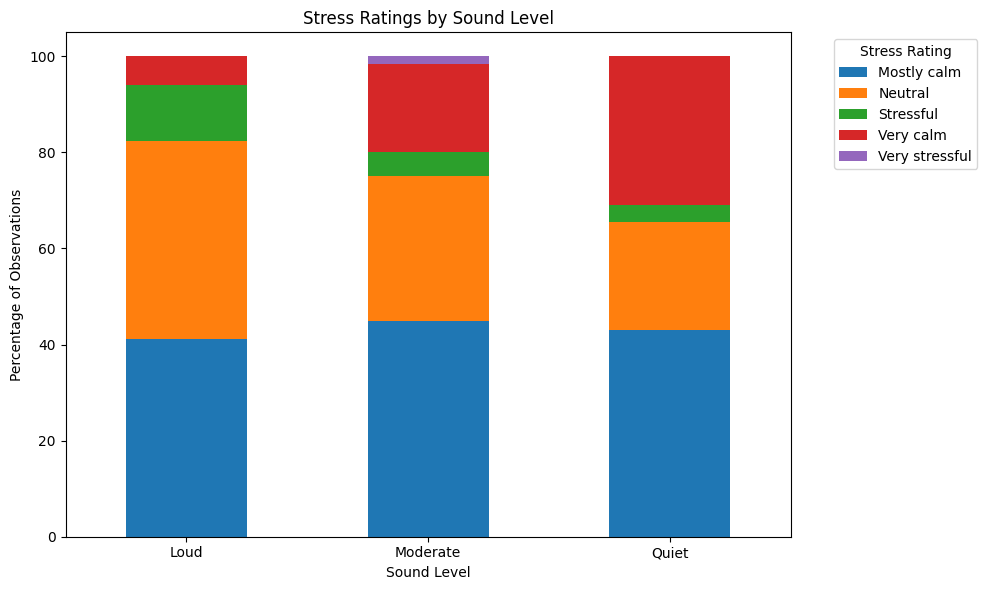

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

sound_stress = pd.crosstab(
    df_clean['sound level'],
    df_clean['stress_rating'],
    normalize='index'
) * 100

display(sound_stress.round(1))

sound_stress.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Stress Ratings by Sound Level')
plt.xlabel('Sound Level')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Stress Rating', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

###Interpretation - Stress Rating by Sound Level

I chose to use a stacked bar chart because I wanted to compare the different stress ratings across loud, moderate and quiet environments. I first learned how to use this type of chart during a Maths Lab, so I was already familiar with it. I thought it would be a good way to visualise the results because it allows me to compare the percentages of each stress category across different sound levels.

Looking at the graph, I noticed that quiet environments had the highest percentage of people reporting feeling very calm (31%), compared with moderate environments (18.3%) and loud environments (5.9%).

I also noticed that the percentage of stressful ratings was higher in loud environments (11.8%) than in quiet environments (3.4%).

I found this interesting because it suggests that quieter environments may be associated with feeling calmer, while louder environments may be associated with higher stress levels.

However, I understand that this graph does not prove that noise directly causes stress, as other environmental factors could also influence how people feel.

Creating this graph helped me apply something I had previously learned during my Maths Lab to a real dataset. It also helped me begin investigating the relationship between environmental characteristics and human experience, which is the main research question of my project.

##Exploring Trees and Wellbeing

###Explanation - Comparing Tree Presence and Wellbeing

In this section, I want to investigate whether the number of trees observed around campus is related to people's wellbeing.

I will use the `trees_presence` and `wellbeing_rating` columns from my cleaned dataset. Both columns contain categorical data, so I will use `pd.crosstab()` to compare the responses and calculate percentages.

I also noticed that five observations have missing tree-presence values, so these will not be included in the comparison.

Wellbeing Ratings by Tree Presence:


wellbeing_rating,Low wellbeing,Neutral,Positive wellbeing,Very low wellbeing,Very positive wellbeing
trees_presence,,,,,
Many,5.9,28.7,48.5,1.0,15.8
One or two,3.4,27.6,58.6,3.4,6.9


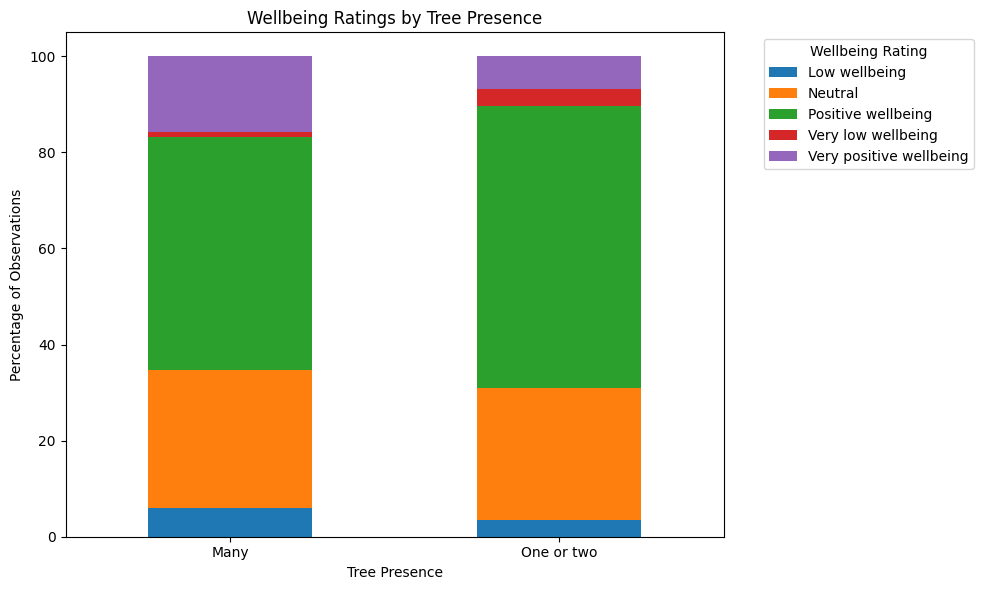

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

#Calculate percentages for each tree-presence category
trees_wellbeing = pd.crosstab(
    df_clean['trees_presence'],
    df_clean['wellbeing_rating'],
    normalize='index'
) * 100

print("Wellbeing Ratings by Tree Presence:")
display(trees_wellbeing.round(1))

#Create a stacked bar chart
trees_wellbeing.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Wellbeing Ratings by Tree Presence')
plt.xlabel('Tree Presence')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)

plt.legend(
    title='Wellbeing Rating',
    bbox_to_anchor=(1.05, 1)
)

plt.tight_layout()
plt.show()


###Interpretation - Wellbeing Ratings by Tree Presence

I chose to use a stacked bar chart again because I found it useful when comparing sound levels and stress ratings.

Looking at the graph, I noticed that observations where many trees were present had a higher percentage of very positive wellbeing ratings (15.8%) compared with observations where only one or two trees were present (6.9%).

However, I also noticed that positive wellbeing ratings were higher in areas with one or two trees (58.6%) compared with areas with many trees (48.5%).

I found this interesting because I initially thought that having more trees would always be associated with better wellbeing, but the graph showed that the relationship is not so simple.

This helped me understand that data analysis can sometimes give unexpected results and that it is important to look at all the categories rather than focusing on just one.

I also understand that the graph does not prove that trees directly affect wellbeing, because other environmental factors could influence how people feel. In addition, there were fewer observations in the one-or-two-trees category, which could affect the comparison.

#**Preparing Variables for Correlation Analysis**

###Explanation - Encoding Categorical Variables

In this section, I want to prepare some of the variables in my dataset for correlation analysis.

I noticed that several columns contain text values instead of numbers, such as Quiet, Moderate and Loud for sound levels.

To analyse relationships between these variables, I need to convert suitable categories into numerical values. I learned from my lecturer's example that this process is called encoding.

I will use ordinal encoding for variables that have a natural order. For example, sound levels can be ordered from Quiet to Moderate to Loud.

I will keep the original columns unchanged and create new encoded columns. This will allow me to compare the original values with the numerical values and check that the encoding worked correctly.

In [29]:
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

#Create a new numerical column for sound levels
df_clean['sound_level_encoded'] = df_clean['sound level'].map(sound_mapping)

display(
    df_clean[['sound level', 'sound_level_encoded']]
    .drop_duplicates()
    .sort_values(by='sound_level_encoded')
)

#Check for missing or unmapped values
print("\nUnmapped values:")
print(df_clean['sound_level_encoded'].isnull().sum())

,sound level,sound_level_encoded
0,Quiet,0
1,Moderate,1
32,Loud,2



Unmapped values:
0


###Interpretation - Sound Level Encoding

I converted the sound levels into numerical values because I wanted to prepare my dataset for correlation analysis.

I used ordinal encoding because the sound levels have a natural order: Quiet, Moderate and Loud. I assigned 0 to Quiet, 1 to Moderate and 2 to Loud.

After running the code, I checked the results and confirmed that all three sound categories were converted correctly, with no unmapped values.

I also kept the original sound level column unchanged so I could still use the original categories when interpreting the data.

##Foot Traffic Encoding


I decided to encode the foot traffic column because I wanted to prepare another environmental variable for correlation analysis.

Foot traffic is ordinal categorical data because its categories have a natural order: Low, Moderate and High.

I will assign numerical values from 0 to 2 and create a new column so I can keep the original data unchanged. I will then check that all the values have been converted correctly.

In [31]:
df_clean['foot_traffic'] = (
    df_clean['foot_traffic']
    .str.strip()
    .str.capitalize()
)

foot_traffic_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

df_clean['foot_traffic_encoded'] = (
    df_clean['foot_traffic'].map(foot_traffic_mapping)
)

print("Foot Traffic Encoding:")

display(
    df_clean[['foot_traffic', 'foot_traffic_encoded']]
    .drop_duplicates()
    .sort_values(by='foot_traffic_encoded')
)

print("\nUnmapped values:")
print(df_clean['foot_traffic_encoded'].isnull().sum())


Foot Traffic Encoding:


,foot_traffic,foot_traffic_encoded
0,Low,0
12,Moderate,1
30,High,2



Unmapped values:
0


###Interpretation - Foot Traffic Encoding

I converted the foot traffic categories into numerical values because I wanted to prepare my dataset for correlation analysis.

When I first ran the code, I noticed that one value was not encoded correctly. After checking the results, I discovered that one observation was written as `low` instead of `Low`.

I corrected this by standardising the text values and then using ordinal encoding to assign Low = 0, Moderate = 1 and High = 2.

After running the code again, all the categories were successfully converted, with zero unmapped values.

##Wellbeing Rating Encoding

###Explanation - Wellbeing Rating Encoding

In this section, I want to convert the wellbeing ratings into numerical values to prepare my dataset for correlation analysis.

The wellbeing ratings are ordinal categorical data because they have a natural order, from very low wellbeing to very positive wellbeing.

I will use numerical values from 0 to 4 and create a new column while keeping the original wellbeing ratings unchanged. I will then check the results to make sure all categories have been encoded correctly.

In [33]:
wellbeing_mapping = {
    'Very low wellbeing': 0,
    'Low wellbeing': 1,
    'Neutral': 2,
    'Positive wellbeing': 3,
    'Very positive wellbeing': 4
}

df_clean['wellbeing_encoded'] = (
    df_clean['wellbeing_rating'].map(wellbeing_mapping)
)

print("Wellbeing Rating Encoding:")

display(
    df_clean[['wellbeing_rating', 'wellbeing_encoded']]
    .drop_duplicates()
    .sort_values(by='wellbeing_encoded')
)

print("\nUnmapped values:")
print(df_clean['wellbeing_encoded'].isnull().sum())


Wellbeing Rating Encoding:


,wellbeing_rating,wellbeing_encoded
22,Very low wellbeing,0
23,Low wellbeing,1
6,Neutral,2
0,Positive wellbeing,3
9,Very positive wellbeing,4



Unmapped values:
0


###Interpretation - Wellbeing Rating Encoding

I converted the wellbeing ratings into numerical values because I wanted to prepare my dataset for correlation analysis.

I used ordinal encoding because the wellbeing categories have a natural order, from very low wellbeing to very positive wellbeing.

I assigned values from 0 to 4, with 0 representing very low wellbeing and 4 representing very positive wellbeing.

After running the code, I checked the results and confirmed that all five categories were converted correctly, with zero unmapped values.

##Stress Rating Encoding

###Explanation - Stress Rating Encoding

In this section, I want to convert the stress ratings into numerical values to prepare my dataset for correlation analysis.

The stress ratings are ordinal categorical data because they have a natural order, from very calm to very stressful.

I decided to use ordinal encoding, assigning values from 0 to 4, where 0 represents very calm and 4 represents very stressful.

I will create a new column called `stress_encoded` while keeping the original stress ratings unchanged. I will then check that all categories have been converted correctly.

In [34]:
stress_mapping = {
    'Very calm': 0,
    'Mostly calm': 1,
    'Neutral': 2,
    'Stressful': 3,
    'Very stressful': 4
}

df_clean['stress_encoded'] = (
    df_clean['stress_rating'].map(stress_mapping)
)

print("Stress Rating Encoding:")

display(
    df_clean[['stress_rating', 'stress_encoded']]
    .drop_duplicates()
    .sort_values(by='stress_encoded')
)

print("\nUnmapped values:")
print(df_clean['stress_encoded'].isnull().sum())


Stress Rating Encoding:


,stress_rating,stress_encoded
6,Very calm,0
2,Mostly calm,1
1,Neutral,2
0,Stressful,3
22,Very stressful,4



Unmapped values:
0


###Interpretation - Stress Rating Encoding

I used ordinal encoding to convert the five stress categories into numerical values, from Very calm = 0 to Very stressful = 4.

After running the code, I checked the results to make sure the numerical values matched the original stress categories.

This helped me understand how stress ratings can be represented numerically so that I can use them in correlation analysis.

By keeping the original column unchanged, I can still compare the numerical values with the original responses when interpreting my results.

##Ease Rating Encoding

###Explanation - Ease Rating Encoding

In this section, I want to convert the ease ratings into numerical values to prepare my dataset for correlation analysis.

The ease ratings describe how comfortable or at ease people felt during the campus walk. These ratings are categorical data, and I need to check their categories before assigning numerical values.

I will use ordinal encoding if the categories have a natural order. I will also keep the original column unchanged so I can compare the encoded values with the original responses.

In [35]:
print("Ease Rating Categories:")
print(df_clean['ease_rating'].value_counts(dropna=False))

print("\nUnique values:")
print(df_clean['ease_rating'].unique())


Ease Rating Categories:
ease_rating
Easy              58
Neutral           38
Vey easy          23
Slighly uneasy    15
Very uneasy        1
Name: count, dtype: int64

Unique values:
['Neutral' 'Easy' 'Vey easy' 'Very uneasy' 'Slighly uneasy']


###Encode Ease Ratings

In [36]:
ease_mapping = {
    'Very uneasy': 0,
    'Slightly uneasy': 1,
    'Neutral': 2,
    'Easy': 3,
    'Very easy': 4
}

df_clean['ease_encoded'] = (
    df_clean['ease_rating'].map(ease_mapping)
)

print("Ease Rating Encoding:")

display(
    df_clean[['ease_rating', 'ease_encoded']]
    .drop_duplicates()
    .sort_values(by='ease_encoded')
)

print("\nUnmapped values:")
print(df_clean['ease_encoded'].isnull().sum())

print("\nData types:")
print(df_clean[['ease_rating', 'ease_encoded']].dtypes)


Ease Rating Encoding:


,ease_rating,ease_encoded
22,Very uneasy,0.0
0,Neutral,2.0
2,Easy,3.0
7,Vey easy,NaN
24,Slighly uneasy,NaN



Unmapped values:
38

Data types:
ease_rating      object
ease_encoded    float64
dtype: object


###Interpretation - Ease Rating Encoding

I used ordinal encoding to convert the five ease rating categories into numerical values, from Very uneasy = 0 to Very easy = 4.

After checking the original categories, I noticed that Easy was the most common response, with 58 observations, followed by Neutral with 38 observations. Only one observation was rated Very uneasy.

I chose this encoding because the categories have a natural order, from feeling very uneasy to feeling very comfortable.

After running the code, I checked that the numerical values matched the original categories and that there were no unmapped values.

##Correlation Analysis

###Explanation - Correlation Matrix

In this section, I want to investigate possible relationships between environmental characteristics and human experiences around the campus.

I decided to create a correlation matrix because my lecturer demonstrated this method during the lab, and I thought it would be useful for comparing several variables together.

I will use the numerical columns I created during the encoding process, including sound levels, foot traffic, wellbeing, stress and ease ratings.

I will use a Spearman correlation because my encoded variables represent ordered categories. The correlation values will help me explore whether variables tend to increase or decrease together.

I understand that correlation does not prove causation and that other environmental factors could influence the results.

Missing values:
sound_level_encoded      0
foot_traffic_encoded     0
wellbeing_encoded        0
stress_encoded           0
ease_encoded            38
dtype: int64


,sound_level_encoded,foot_traffic_encoded,wellbeing_encoded,stress_encoded,ease_encoded
sound_level_encoded,1.00,0.56,-0.13,0.23,-0.07
foot_traffic_encoded,0.56,1.00,-0.05,0.14,-0.08
wellbeing_encoded,-0.13,-0.05,1.00,-0.60,0.46
stress_encoded,0.23,0.14,-0.60,1.00,-0.48
ease_encoded,-0.07,-0.08,0.46,-0.48,1.00


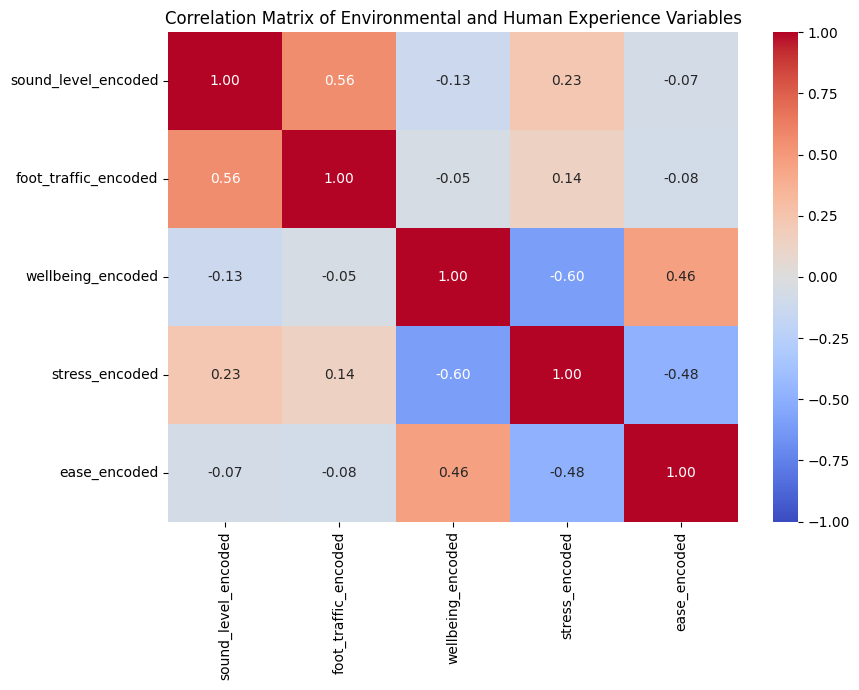

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    'sound_level_encoded',
    'foot_traffic_encoded',
    'wellbeing_encoded',
    'stress_encoded',
    'ease_encoded'
]

correlation_data = df_clean[correlation_columns]

print("Missing values:")
print(correlation_data.isnull().sum())

correlation_matrix = correlation_data.corr(method='spearman')

display(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f'
)

plt.title('Correlation Matrix of Environmental and Human Experience Variables')
plt.tight_layout()
plt.show()


###Interpretation - Correlation Matrix Heatmap

I used Spearman correlation because the variables I encoded are ordinal categorical data. The heatmap helped me compare several variables at the same time using colours and numerical values.

Looking at the results, I noticed that sound levels and foot traffic had a moderate positive correlation of 0.56. This suggests that areas with more foot traffic also tend to have higher sound levels, which I found interesting.

I also noticed a moderate negative correlation between wellbeing and stress (-0.60). This suggests that observations with higher wellbeing ratings tend to have lower stress ratings.

Another interesting result was the positive correlation between wellbeing and ease (0.46), suggesting that people who felt more at ease also tended to report better wellbeing.

The correlation between sound levels and stress was only 0.23, which indicates a weak positive relationship. I found this interesting because I initially expected sound levels to have a stronger relationship with stress.